--- Pemilih Metrik Lohong Hitam (Berdasarkan Framework Tesis) ---
1: Schwarzschild (Standard)
2: Reissner-Nordström (Bercas Q)
3: Kottler / S-deSitter (Pemalar Lambda)
4: Bardeen (Regular / Tanpa Singularity)
5: Schwarzschild-Anti-de Sitter (SAdS)
6: Hayward (Regular / Teras Quantum)
7: Kiselev (Quintessence Fluid)
8: Mannheim-Kazanas (Conformal Gravity)

Metrik yang dipilih ialah metrik Kiselev (Quintessence Fluid)

--- event horizon ---


Eq(event_horizon, 2.25403330758517)

event_{horizon} = 2.25403330758517


--- lapse function ---


Eq(lapse, -2*M/r - a*r**(-3*w - 1) + 1)

lapse = - \frac{2 M}{r} - a r^{- 3 w - 1} + 1


--- 1. LAGRANGIAN (L) ---


...

b = 6.89560699462891


--- 6. ORBITAL EQUATION (dr/dphi)^2 ---


Eq(dr_dphi_square, 2.0*M*r + 1.0*a*r/r**(3*w) - 1.0*r**2 + 1.0*r**4/b**2)

dr_{dphi square} = 2.0 M r + 1.0 a r r^{- 3 w} - 1.0 r^{2} + \frac{1.0 r^{4}}{b^{2}}


--- 7. ODE FOR SOLVER (dr/dphi) ---


Eq(dr_dphi, sqrt(2.0*M*r + 1.0*a*r/r**(3*w) - 1.0*r**2 + 1.0*r**4/b**2))

dr_{dphi} = \sqrt{2.0 M r + 1.0 a r r^{- 3 w} - 1.0 r^{2} + \frac{1.0 r^{4}}{b^{2}}}


Firing photons...


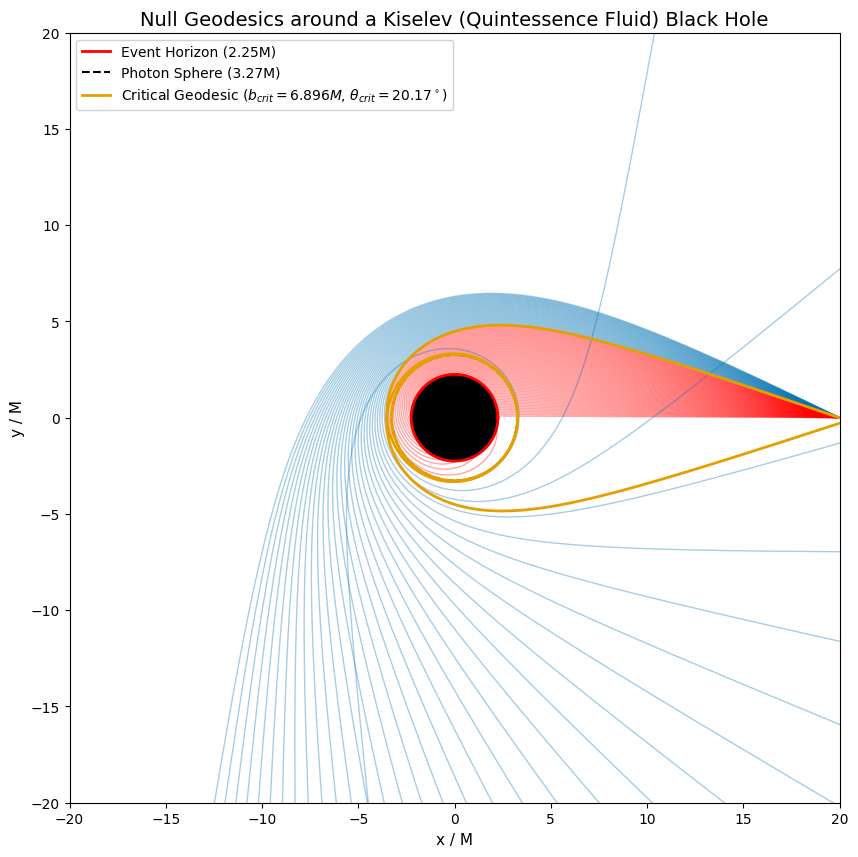

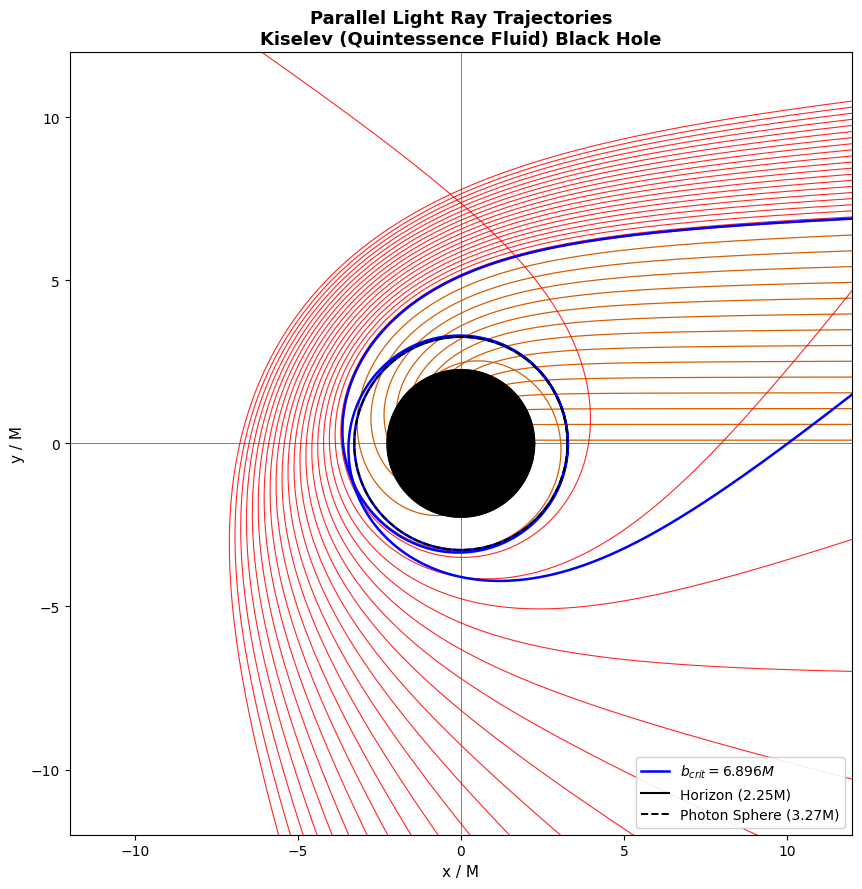

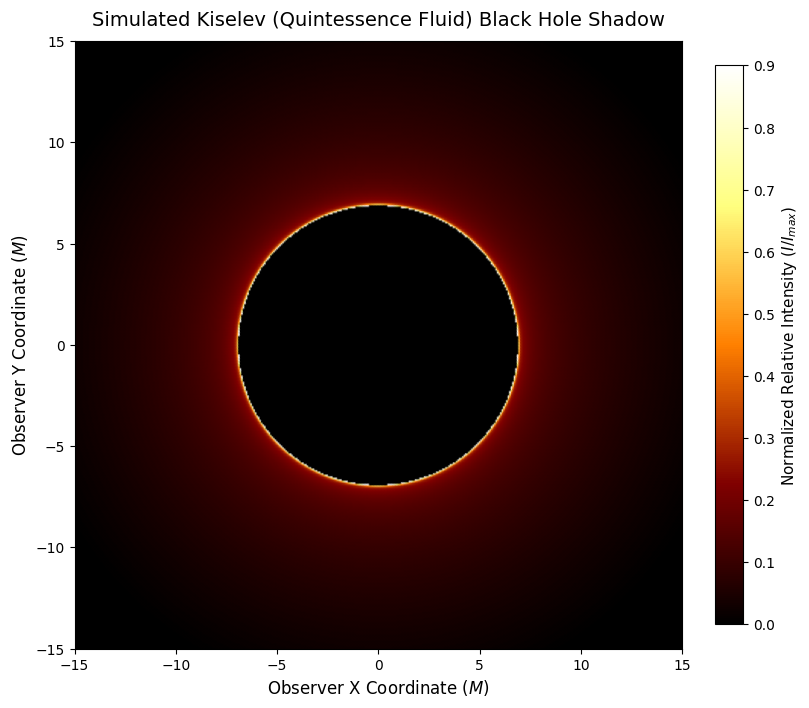

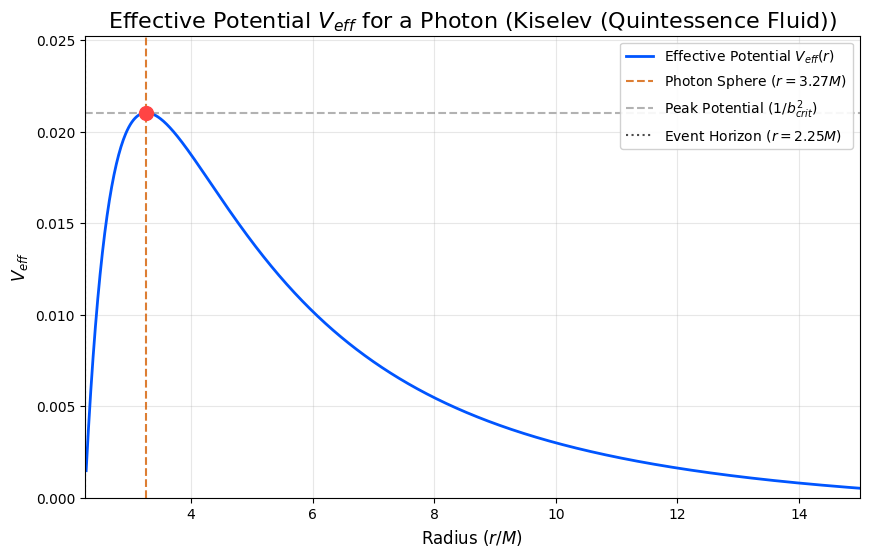

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from matplotlib.colors import LinearSegmentedColormap, LightSource, Normalize
from sympy import *

# Fallback for display if running outside Jupyter Notebooks
try:
    from IPython.display import display
except ImportError:

    def display(expr):
        print(expr)


def automated_black_hole_engine():
    # 1. SETUP SYMBOLS (Unit natural G = c = 1)
    r, M, b = sp.symbols('r M b', positive=True, real=True)
    E, L = sp.symbols('E L', positive=True, real=True)
    A = sp.symbols('A')  # for kottler (cosmological constant)
    v = sp.symbols('v')
    Q = sp.symbols(
        'Q', positive=True, real=True
    )  # for reissner-nordstrom (charge)
    g = sp.symbols('g')  # for bardeen metric (the magnetic monopole charge)
    l = sp.symbols('l')  # for hayward (the fundamental length scale)
    Ads = sp.symbols('Ads')  # for sAds metric (the Ads curvature radius)
    a = sp.symbols('a')  # for kiselev metric (quintessence density)
    w = sp.symbols('w')  # for kiselev metric (equation of state)
    y = sp.symbols('y')  # for mannheim-kazanas (the conformal parameter)
    k = sp.symbols('k')  # for mannheim-kazanas (the conformal parameter)

    print('--- Pemilih Metrik Lohong Hitam (Berdasarkan Framework Tesis) ---')
    metrics = {
        '1': 'Schwarzschild (Standard)',
        '2': 'Reissner-Nordström (Bercas Q)',
        '3': 'Kottler / S-deSitter (Pemalar Lambda)',
        '4': 'Bardeen (Regular / Tanpa Singularity)',
        '5': 'Schwarzschild-Anti-de Sitter (SAdS)',
        '6': 'Hayward (Regular / Teras Quantum)',
        '7': 'Kiselev (Quintessence Fluid)',
        '8': 'Mannheim-Kazanas (Conformal Gravity)',
    }

    for key, name in metrics.items():
        print(f'{key}: {name}')

    choice = input('Pilih nombor metrik (1-8): ')
    print(
        f"\nMetrik yang dipilih ialah metrik {metrics.get(choice, 'Invalid Choice')}\n"
    )

    params = {M: sp.Integer(1)}
    if choice == '1':
        f_r = 1 - 2 * M / r
    elif choice == '2':
        f_r = 1 - 2 * M / r + Q**2 / r**2
        params[Q] = sp.Rational(1, 2)
    elif choice == '3':
        f_r = 1 - 2 * M / r - (A * r**2 / 3)
        params[A] = sp.Rational(1, 100)
    elif choice == '4':
        f_r = 1 - (2 * M * r**2) / (r**2 + g**2) ** (sp.Rational(3, 2))
        params[g] = sp.Rational(3, 5)
    elif choice == '5':
        f_r = 1 - 2 * M / r + r**2 / Ads**2
        params[Ads] = sp.Integer(10)
    elif choice == '6':
        f_r = 1 - (2 * M * r**2) / (r**3 + 2 * M * l**2)
        params[l] = sp.Rational(1, 2)
    elif choice == '7':
        f_r = 1 - 2 * M / r - a / r ** (3 * w + 1)
        params[a] = sp.Rational(1, 20)
        params[w] = sp.Rational(-2, 3)
    elif choice == '8':
        f_r = 1 - 2 * M / r + y * r - k * r**2
        params[y] = sp.Rational(3, 10**28)
        params[k] = sp.Rational(954, 10**52)
    else:
        print('Pilihan tidak sah.')
        return

    M = 1.0
    # =====================================================================
    # DYNAMIC HORIZON CALCULATOR
    # =====================================================================
    f_r_numeric = f_r.subs(params)

    if choice in ['4']:
        r_h_val = float(sp.nsolve(f_r_numeric, r, 2.0))

    try:
        roots = sp.solve(f_r_numeric, r)
        real_roots = [
            float(sp.re(sol)) for sol in roots if sol.is_real or sol.is_Atom
        ]
        r_h_val = min(real_roots, key=lambda x: abs(float(x.evalf()) - 2.0))
    except:
        r_h_val = float(sp.nsolve(f_r_numeric, r, 2.0))

    event_horizon = sp.symbols('event_horizon')

    print("--- event horizon ---")
    display(Eq(event_horizon, r_h_val))
    print_latex(Eq(event_horizon, r_h_val))
    print("\n")

    # =====================================================================
    # 1. DEFINE SYMBOLIC VARIABLES
    # =====================================================================
    t_dot, r_dot, phi_dot = sp.symbols('t_dot r_dot phi_dot', real=True)
    dr_dphi = sp.symbols('dr_dphi')
    lagrangian = sp.symbols('lagrangian')
    r_dot_square = sp.symbols('r_dot_square')
    dr_dphi_square = sp.symbols('dr_dphi_square')
    lapse = sp.symbols('lapse')

    print("--- lapse function ---")
    display(Eq(lapse, f_r))
    print_latex(Eq(lapse, f_r))
    print("\n")

    # =====================================================================
    # 2. DERIVE THE LAGRANGIAN 
    # =====================================================================
    L_expr = 0.5 * (-f_r * t_dot**2 + (1 / f_r) * r_dot**2 + r**2 * phi_dot**2)

    print("--- 1. LAGRANGIAN (L) ---")
    display(Eq(lagrangian, L_expr))
    print_latex(Eq(lagrangian, L_expr))
    print("\n")

    # =====================================================================
    # 3. DERIVE CONSTANTS OF MOTION (E and L)
    # =====================================================================
    p_t = sp.diff(L_expr, t_dot)
    eq_E = sp.Eq(p_t, -E)
    t_dot_sol = sp.solve(eq_E, t_dot)[0]

    p_phi = sp.diff(L_expr, phi_dot)
    eq_L = sp.Eq(p_phi, L)
    phi_dot_sol = sp.solve(eq_L, phi_dot)[0]

    print("--- 2. CONSTANTS OF MOTION ---")
    display(Eq(t_dot, t_dot_sol))
    print_latex(Eq(t_dot, t_dot_sol))
    print("\n")
    display(Eq(phi_dot, phi_dot_sol))
    print_latex(Eq(phi_dot, phi_dot_sol))
    print("\n")

    # =====================================================================
    # 4. DERIVE RADIAL VELOCITY AND EFFECTIVE POTENTIAL
    # =====================================================================
    L_subbed = L_expr.subs({t_dot: t_dot_sol, phi_dot: phi_dot_sol})

    eq_r_dot = sp.Eq(L_subbed * 2, 0)
    r_dot_squared_sol = sp.solve(eq_r_dot, r_dot**2)[0]

    print("--- 3. RADIAL VELOCITY (r_dot^2) ---")
    display(Eq(r_dot_square, r_dot_squared_sol))
    print_latex(Eq(r_dot_square, r_dot_squared_sol))
    print("\n")

    V_r = f_r / r**2

    print("--- 4. EFFECTIVE POTENTIAL V(r) ---")
    display(Eq(v, V_r))
    print_latex(Eq(v, V_r))
    print("\n")

    # =====================================================================
    # 5. FIND THE PHOTON SPHERE AND CRITICAL IMPACT PARAMETER
    # =====================================================================
    # Set dV/dr = 0 and solve for r
    dV_dr = sp.diff(V_r, r)
    display(dV_dr)
    try:

        if choice in ['4']:
            raise ValueError("Analytical derivation too complex. Bypassing sp.solve.")
        
        # 1. ATTEMPT EXACT ANALYTICAL SOLUTION
        # This works perfectly for Schwarzschild, Reissner-Nordström, and Kottler
        r_ph_solutions = sp.solve(dV_dr.subs(params), r)
        
        # If SymPy cannot find a solution, it returns an empty list []. 
        # We manually trigger an error here so it jumps to the numerical solver.
        if not r_ph_solutions:
            raise ValueError("No analytical solution found.")
            
        display(r_ph_solutions)
        
        # Get the valid root 
        # (For simple metrics, [0] is usually the correct positive root)
        # Ensure we only pick the positive real root that is outside the horizon
        r_ph_final = max([sol for sol in r_ph_solutions if sol.is_real and float(sol.evalf()) > float(r_h_val.evalf())])
        
        # Calculate max potential and critical impact parameter symbolically
        V_max = V_r.subs(params).subs(r, r_ph_final)
        b_crit = 1 / sp.sqrt(V_max)
        b_crit_final = sp.simplify(b_crit)
        
        print("\n[Status: Analytical Derivation Successful]")

    except Exception:
        # 2. NUMERICAL FALLBACK
        # If exact math fails (Bardeen, Hayward, Kiselev, etc.), switch to Numerical Solver
        print("\n[Status: Analytical derivation too complex. Switching to Numerical Solver...]")
        
        # Substitute our numerical parameters (M=1.0, g=0.6, etc.) into the equation FIRST
        dV_dr_numeric = dV_dr.subs(params)
        
        # sp.nsolve uses numerical approximation to find the root. We give it an initial guess of r=3.0
        r_ph_numeric = sp.nsolve(dV_dr_numeric, r, 3.0)
        
        # Convert to a SymPy Float (rounded to 5 decimal places) so it prints nicely in LaTeX
        r_ph = sp.Float(r_ph_numeric, 5) 
        
        # Calculate max potential and critical impact parameter numerically
        V_max_numeric = V_r.subs(r, r_ph_numeric).subs(params)
        b_critical_numeric = 1 / sp.sqrt(V_max_numeric)
        
        # Convert to a SymPy Float for nice LaTeX display
        b_critical = sp.Float(b_critical_numeric, 5)

        r_ph_final = r_ph * M
        b_crit_final = b_critical * M
    print("--- 5. OPTICAL BOUNDARIES ---")
    print(f"Photon Sphere radius (r_ph): {r_ph_final}") 
    display(Eq(r,r_ph_final))
    print_latex(Eq(r,r_ph_final))
    print("\n")
    print(f"Critical Impact Parameter (b_crit): {b_crit_final}") 
    display(Eq(b,b_crit_final))
    print_latex(Eq(b,b_crit_final))
    print("\n")

    # =====================================================================
    # 6. DERIVE THE ORBITAL EQUATION (dr/dphi)^2 AND dr/dphi
    # =====================================================================
    dr_dphi_squared = r_dot_squared_sol / (phi_dot_sol**2)
    dr_dphi_squared_b = dr_dphi_squared.subs(E**2, (L / b)**2)
    dr_dphi_squared_final = sp.simplify(dr_dphi_squared_b)
    dr_dphi_final = sp.sqrt(dr_dphi_squared_final)

    print("--- 6. ORBITAL EQUATION (dr/dphi)^2 ---")
    display(Eq(dr_dphi_square, dr_dphi_squared_final))
    print_latex(Eq(dr_dphi_square, dr_dphi_squared_final))
    print("\n")
    print("--- 7. ODE FOR SOLVER (dr/dphi) ---")
    display(Eq(dr_dphi, dr_dphi_final))
    print_latex(Eq(dr_dphi, dr_dphi_final))
    print("\n")

    # ==========================================
    # Simulation setup
    # ==========================================
    u_sym = sp.symbols('u', positive=True)
    f_u = f_r.subs(r, 1 / u_sym)
    H_u = f_u * u_sym**2
    dH_du = sp.diff(H_u, u_sym)
    rhs = -sp.Rational(1, 2) * dH_du

    rhs_numeric = rhs.subs(params)
    u_double_prime = sp.lambdify(u_sym, rhs_numeric, modules='numpy')
    f_u_func = sp.lambdify(u_sym, f_u.subs(params), modules='numpy')

    def runge_kutta_4_step(u, u_prime, d_phi):
        k1_u = u_prime
        k1_up = u_double_prime(u)

        k2_u = u_prime + 0.5 * d_phi * k1_up
        k2_up = u_double_prime(u + 0.5 * d_phi * k1_u)

        k3_u = u_prime + 0.5 * d_phi * k2_up
        k3_up = u_double_prime(u + 0.5 * d_phi * k2_u)

        k4_u = u_prime + d_phi * k3_up
        k4_up = u_double_prime(u + d_phi * k3_u)

        u_new = u + (d_phi / 6.0) * (k1_u + 2 * k2_u + 2 * k3_u + k4_u)
        u_prime_new = u_prime + (d_phi / 6.0) * (
            k1_up + 2 * k2_up + 2 * k3_up + k4_up
        )

        return u_new, u_prime_new

    def trace_photon(b_val, step_size=0.02, max_steps=7000):
        r_obs = 20.0
        if b_val == 0:
            return [r_obs, 0], [0, 0], 'captured'

        if b_val >= r_obs:
            return [r_obs], [0], 'escaped'

        initial_phi = np.arcsin(b_val / r_obs)
        u_val = 1.0 / r_obs

        f_u_start = f_u_func(u_val)
        u_p_sq = (1.0 / b_val**2) - (f_u_start * u_val**2)

        if u_p_sq < 0:
            return [r_obs], [0], 'escaped'

        u_prime = np.sqrt(u_p_sq)
        x_vals, y_vals = [], []
        current_phi = initial_phi

        for _ in range(max_steps):
            r_val = 1.0 / u_val if u_val > 0 else 1e10
            x = r_val * np.cos(current_phi - initial_phi)
            y = r_val * np.sin(current_phi - initial_phi)

            x_vals.append(x)
            y_vals.append(y)

            if r_val <= r_h_val * 1.01:
                return x_vals, y_vals, 'captured'
            if r_val > r_obs * 2.0 or u_val < 0:
                return x_vals, y_vals, 'escaped'

            u_val, u_prime = runge_kutta_4_step(u_val, u_prime, step_size)
            current_phi += step_size

        return x_vals, y_vals, 'escaped'

    b_crit = (
        float(b_crit_final.subs(params))
        if b_crit_final.free_symbols
        else float(b_crit_final)
    )
    r_ph_val = (
        float(r_ph_final.subs(params))
        if r_ph_final.free_symbols
        else float(r_ph_final)
    )

    impact_parameters = np.linspace(0.1, 10.0, 100)

    # ==========================================
    # --- CALCULATE CRITICAL OBSERVER ANGLE ---
    # ==========================================

    r_obs = 20.0
    theta_crit_rad = np.arcsin(np.clip(b_crit / r_obs, -1.0, 1.0))
    theta_crit_deg = np.degrees(theta_crit_rad)

    impact_parameters = np.linspace(0.1, 10.0, 100)

    # ==========================================
    # --- SIMULATION 1: NULL GEODESICS (WITH CRITICAL ANGLE LEGEND) ---
    # ==========================================
    
    plt.style.use('default')
    plt.figure(figsize=(10, 10), facecolor='white')
    print('Firing photons...')

    for b_val in impact_parameters:
        x_arr, y_arr, status = trace_photon(b_val)
        color_line = 'red' if status == 'captured' else '#0072B2'
        plt.plot(x_arr, y_arr, color=color_line, alpha=0.35, linewidth=1)

    theta = np.linspace(0, 2 * np.pi, 200)
    eh_x = r_h_val * np.cos(theta)
    eh_y = r_h_val * np.sin(theta)
    plt.fill(eh_x, eh_y, color='black', zorder=5)
    plt.plot(
        eh_x,
        eh_y,
        color='red',
        linewidth=2,
        zorder=5,
        label=f'Event Horizon ({r_h_val:.2f}M)',
    )

    ps_x = r_ph_val * np.cos(theta)
    ps_y = r_ph_val * np.sin(theta)
    plt.plot(
        ps_x,
        ps_y,
        color='black',
        linestyle='--',
        linewidth=1.5,
        zorder=4,
        label=f'Photon Sphere ({r_ph_val:.2f}M)',
    )

    x_c, y_c, _ = trace_photon(b_crit)
    plt.plot(
        x_c,
        y_c,
        color='#E69F00',
        linewidth=2,
        label=f'Critical Geodesic ($b_{{crit}} = {b_crit:.3f}M$, $\\theta_{{crit}} = {theta_crit_deg:.2f}^\\circ$)',
        zorder=10,
    )

    plt.title(
        f'Null Geodesics around a {metrics[choice]} Black Hole', fontsize=14
    )
    plt.xlabel('x / M', fontsize=11)
    plt.ylabel('y / M', fontsize=11)
    plt.xlim(-20, 20)
    plt.ylim(-20, 20)
    plt.legend(loc='upper left', framealpha=0.9, fontsize=10)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.savefig('null_geodesics.png', dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close()

    # ==========================================
    # SIMULATION 2: PARALLEL RAY TRACING (WHITE BACKGROUND)
    # ==========================================

    def trace_parallel_ray(
        b_val,
        x0,
        f_u_func_in,
        u_double_prime_func_in,
        r_h_in,
        d_phi=0.01,
        max_steps=8000,
    ):
        if b_val == 0:
            return [x0, 0], [b_val, 0], 'captured'

        r0 = np.hypot(x0, b_val)
        phi0 = np.arctan2(b_val, x0)
        u_val = 1.0 / r0

        u_p_sq = (1.0 / b_val**2) - (f_u_func_in(u_val) * u_val**2)
        if u_p_sq < 0:
            return [x0], [b_val], 'escaped'

        u_prime = np.sqrt(u_p_sq)
        current_phi = phi0
        x_vals, y_vals = [], []

        for _ in range(max_steps):
            r_val = 1.0 / u_val if u_val > 0 else 1e10
            x = r_val * np.cos(current_phi)
            y = r_val * np.sin(current_phi)

            x_vals.append(x)
            y_vals.append(y)

            if r_val <= r_h_in * 1.002 or u_val >= (1.0 / r_h_in):
                return x_vals, y_vals, 'captured'
            if r_val > 30.0 or x < -15.0 or y < -15.0 or u_val <= 0:
                return x_vals, y_vals, 'escaped'

            k1_u = u_prime
            k1_up = u_double_prime_func_in(u_val)

            k2_u = u_prime + 0.5 * d_phi * k1_up
            k2_up = u_double_prime_func_in(u_val + 0.5 * d_phi * k1_u)

            k3_u = u_prime + 0.5 * d_phi * k2_up
            k3_up = u_double_prime_func_in(u_val + 0.5 * d_phi * k2_u)

            k4_u = u_prime + d_phi * k3_up
            k4_up = u_double_prime_func_in(u_val + d_phi * k3_u)

            u_val += (d_phi / 6.0) * (k1_u + 2 * k2_u + 2 * k3_u + k4_u)
            u_prime += (d_phi / 6.0) * (k1_up + 2 * k2_up + 2 * k3_up + k4_up)
            current_phi += d_phi

        return x_vals, y_vals, 'escaped'

    x0 = 12.0
    b_captured = np.linspace(0.1, b_crit - 0.02, 15)
    b_escaped = np.linspace(b_crit + 0.05, 10.5, 20)

    plt.figure(figsize=(9, 9), facecolor='white')
    ax = plt.gca()

    for b_val in b_captured:
        x_tr, y_tr, _ = trace_parallel_ray(
            b_val, x0, f_u_func, u_double_prime, r_h_val
        )
        ax.plot(x_tr, y_tr, color='#D55E00', linewidth=0.9, zorder=2)

    for b_val in b_escaped:
        x_tr, y_tr, _ = trace_parallel_ray(
            b_val, x0, f_u_func, u_double_prime, r_h_val
        )
        ax.plot(x_tr, y_tr, color='red', linewidth=0.8, alpha=0.85, zorder=2)

    x_c, y_c, _ = trace_parallel_ray(
        b_crit,
        x0,
        f_u_func,
        u_double_prime,
        r_h_val,
        d_phi=0.003,
        max_steps=12000,
    )
    ax.plot(
        x_c,
        y_c,
        color='blue',
        linewidth=1.8,
        zorder=4,
        label=f'$b_{{crit}} = {b_crit:.3f}M$',
    )

    ax.fill(
        r_h_val * np.cos(theta),
        r_h_val * np.sin(theta),
        color='black',
        zorder=5,
    )
    ax.plot(
        r_h_val * np.cos(theta),
        r_h_val * np.sin(theta),
        color='black',
        linewidth=1.5,
        zorder=6,
        label=f'Horizon ({r_h_val:.2f}M)',
    )
    ax.plot(
        r_ph_val * np.cos(theta),
        r_ph_val * np.sin(theta),
        color='black',
        linestyle='--',
        linewidth=1.4,
        zorder=5,
        label=f'Photon Sphere ({r_ph_val:.2f}M)',
    )

    ax.axhline(0, color='gray', linewidth=0.7, zorder=1)
    ax.axvline(0, color='gray', linewidth=0.7, zorder=1)

    plt.title(
        'Parallel Light Ray Trajectories\n' f'{metrics[choice]} Black Hole',
        fontsize=13,
        fontweight='bold',
    )
    plt.xlabel('x / M', fontsize=11)
    plt.ylabel('y / M', fontsize=11)
    plt.xlim(-12, 12)
    plt.ylim(-12, 12)
    plt.gca().set_aspect('equal')
    plt.legend(loc='lower right', fontsize=10, framealpha=0.9)
    plt.tight_layout()
    plt.savefig(f'parallel_rays_{choice}.png', dpi=300, facecolor='white')
    plt.show()
    plt.close()

    # ==========================================
    # SIMULATION 3: BLACK HOLE SHADOW (WHITE PAPER THEME)
    # ==========================================

    resolution = 400
    fov = 15.0

    x_grid = np.linspace(-fov, fov, resolution)
    y_grid = np.linspace(-fov, fov, resolution)
    X, Y = np.meshgrid(x_grid, y_grid)

    B = np.sqrt(X**2 + Y**2)
    image = np.zeros((resolution, resolution))
    escape_mask = B >= b_crit

    b_escaped_vals = B[escape_mask]
    f_r_func = sp.lambdify(r, f_r.subs(params), modules='numpy')
    f_b = f_r_func(b_escaped_vals)
    redshift_factor = np.clip(f_b, 0.0, 1.0)

    lensing_halo = 1.0 / (b_escaped_vals - b_crit + 0.02) ** 0.3
    photon_ring_peak = np.exp(-((b_escaped_vals - b_crit) ** 2) / 0.005) * 3.0

    brightness = redshift_factor * (lensing_halo + photon_ring_peak)
    image[escape_mask] = brightness

    if np.max(image) > 0:
        image = image / np.max(image)

    fig, ax_sh = plt.subplots(
        figsize=(8, 8), facecolor='white', layout='constrained'
    )
    ax_sh.set_facecolor('black')

    im = ax_sh.pcolormesh(
        X, Y, image, cmap=plt.cm.afmhot, shading='gouraud', vmin=0.0, vmax=0.9
    )

    ax_sh.set_aspect('equal')
    ax_sh.set_title(
        f'Simulated {metrics[choice]} Black Hole Shadow',
        color='black',
        fontsize=14,
        pad=12,
    )
    ax_sh.set_xlabel('Observer X Coordinate ($M$)', color='black', fontsize=12)
    ax_sh.set_ylabel('Observer Y Coordinate ($M$)', color='black', fontsize=12)
    ax_sh.tick_params(colors='black', labelsize=10)

    cbar = fig.colorbar(im, ax=ax_sh, fraction=0.046, pad=0.04)
    cbar.set_label(
        'Normalized Relative Intensity ($I/I_{max}$)',
        color='black',
        fontsize=11,
    )
    cbar.ax.yaxis.set_tick_params(color='black')
    plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='black')

    fig.savefig(
        f'bh_shadow_{choice}.png', dpi=300, bbox_inches='tight', facecolor='white'
    )
    plt.show()
    plt.close(fig)

    # ==========================================
    # SIMULATION 4: EFFECTIVE POTENTIAL GRAPH (WHITE BACKGROUND)
    # ==========================================

    f_r_lambdified = sp.lambdify(r, f_r.subs(params), modules='numpy')
    r_arr = np.linspace(r_h_val * 1.01, 15.0, 1000)
    V_arr = f_r_lambdified(r_arr) / r_arr**2
    V_peak = float(V_r.subs(r, r_ph_val).subs(params))

    plt.style.use('default')
    plt.figure(figsize=(10, 6), facecolor='white')
    plt.plot(
        r_arr,
        V_arr,
        color='#0055ff',
        linewidth=2,
        label='Effective Potential $V_{eff}(r)$',
    )
    plt.scatter([r_ph_val], [V_peak], color='#ff4444', s=100, zorder=5)
    plt.axvline(
        r_ph_val,
        color='#D55E00',
        linestyle='--',
        alpha=0.8,
        label=f'Photon Sphere ($r = {r_ph_val:.2f}M$)',
    )
    plt.axhline(
        V_peak,
        color='gray',
        linestyle='--',
        alpha=0.6,
        label=r'Peak Potential ($1/b_{crit}^2$)',
    )
    plt.axvline(
        r_h_val,
        color='black',
        linestyle=':',
        alpha=0.7,
        label=f'Event Horizon ($r = {r_h_val:.2f}M$)',
    )

    plt.title(
        f'Effective Potential $V_{{eff}}$ for a Photon ({metrics[choice]})',
        fontsize=16,
    )
    plt.xlabel('Radius ($r/M$)', fontsize=12)
    plt.ylabel('$V_{eff}$', fontsize=12)
    plt.xlim(r_h_val, 15.0)
    plt.ylim(0, max(V_arr) * 1.2 if len(V_arr) > 0 else 0.06)
    plt.legend(loc='upper right', framealpha=0.9)
    plt.grid(True, alpha=0.3)
    plt.savefig('veff_plot.png', bbox_inches='tight', facecolor='white', dpi=300)
    plt.show()
    plt.close()


if __name__ == '__main__':
    automated_black_hole_engine()